# Project 5: Fake News Detection Using Transformer Models

**Type:** Natural Language Processing — Transformer-based Classification  
**Problem Statement:** Given a collection of online news articles containing headlines, descriptions, and complete article content, develop an NLP-based system to classify news as potentially misleading or credible using contextual language representations.  
**Expected Outcome:** A transformer-based news classification prototype that estimates whether an article resembles misleading or credible examples in its labelled dataset.

---
## 1. Problem Understanding & Objective Definition

### Real-World Relevance
Online misinformation spreads rapidly through sensationalized headlines, misleading summaries, and fabricated news narratives. Traditional keyword or bag-of-words filters struggle to capture sarcasm, framing, and contextual nuance across full news articles.

### Objectives & Scope
- **Input Representation:** Combine article **Headline**, **Description (lead summary)**, and **Complete Article Content** into a unified contextual sequence.
- **Label Convention:** Binary classification where `0 = Credible` and `1 = Misleading`.
- **Comparative Experiments:** Benchmark classical sparse representations (**TF-IDF + Naive Bayes** and **TF-IDF + Logistic Regression**) against a fine-tuned **Transformer (`distilbert-base-uncased`)** model.
- **Evaluation:** Compare models using **Accuracy, Precision, Recall, F1-Score, ROC-AUC**, confusion matrices, ROC curves, and qualitative error analysis.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"

print("Project Root:", PROJECT_ROOT)

Project Root: C:\Users\hanug\.gemini\antigravity\scratch\fake_news_detection_transformer


---
## 2. Dataset Understanding & Preprocessing

### Dataset & Leakage-Prevention Decisions
We use the `GonzaloA/fake_news` English online news corpus (~40.5k raw articles) and apply rigorous preprocessing in [`src/data_prep.py`](../src/data_prep.py):
1. **Label Normalization:** Standardize labels to `0 = Credible` and `1 = Misleading`.
2. **Data-Leakage Removal:** Strip publisher datelines (e.g., `WASHINGTON (Reuters) - `) and social-media footers (`Featured image via ...`, `Read more: ...`) plus URLs so models learn **contextual writing patterns** instead of memorizing source tags.
3. **Missing Values & Short Text Filtering:** Drop null records and articles with headlines < 10 chars or content < 50 chars.
4. **Global Deduplication:** Deduplicate on normalized `headline + content[:200]` **before** splitting so near-identical articles never leak across Train / Validation / Test splits.
5. **Structured Input Fields:** Extract `headline`, `description` (lead summary sentence), and `content` (full body), then perform a **stratified 70% / 15% / 15% split**.

In [2]:
with open(OUTPUTS_DIR / "eda_summary.json", encoding="utf-8") as f:
    eda_summary = json.load(f)

print(json.dumps(eda_summary, indent=2))

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "val.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print(f"Loaded splits -> Train: {len(train_df):,}, Val: {len(val_df):,}, Test: {len(test_df):,}")
train_df[["headline", "description", "label", "word_count"]].head(3)

{
  "dataset_source": "GonzaloA/fake_news (ISOT-derived online news corpus)",
  "label_mapping": {
    "0": "Credible",
    "1": "Misleading"
  },
  "raw_rows": 40587,
  "missing_before_cleaning": {
    "title": 0,
    "text": 0,
    "label": 0
  },
  "short_or_empty_removed": 343,
  "duplicates_removed": 137,
  "clean_rows": 40107,
  "modeling_rows": 18000,
  "class_balance": {
    "Credible (0)": 9740,
    "Misleading (1)": 8260
  },
  "avg_word_count": {
    "Credible (0)": 399.4,
    "Misleading (1)": 436.7
  },
  "split_sizes": {
    "train": 12600,
    "val": 2700,
    "test": 2700
  }
}
Loaded splits -> Train: 12,600, Val: 2,700, Test: 2,700


,headline,description,label,word_count
0,Britain 'disappointed' with Trump's climate move,British Prime Minister Theresa May told Presid...,0,75
1,Funding to combat Zika fails to advance in Senate,Funding to battle the Zika virus failed to adv...,0,92
2,WATCH: Hillary Exposes The GOP’s Abortion Secr...,Republicans and religious conservatives made a...,1,379


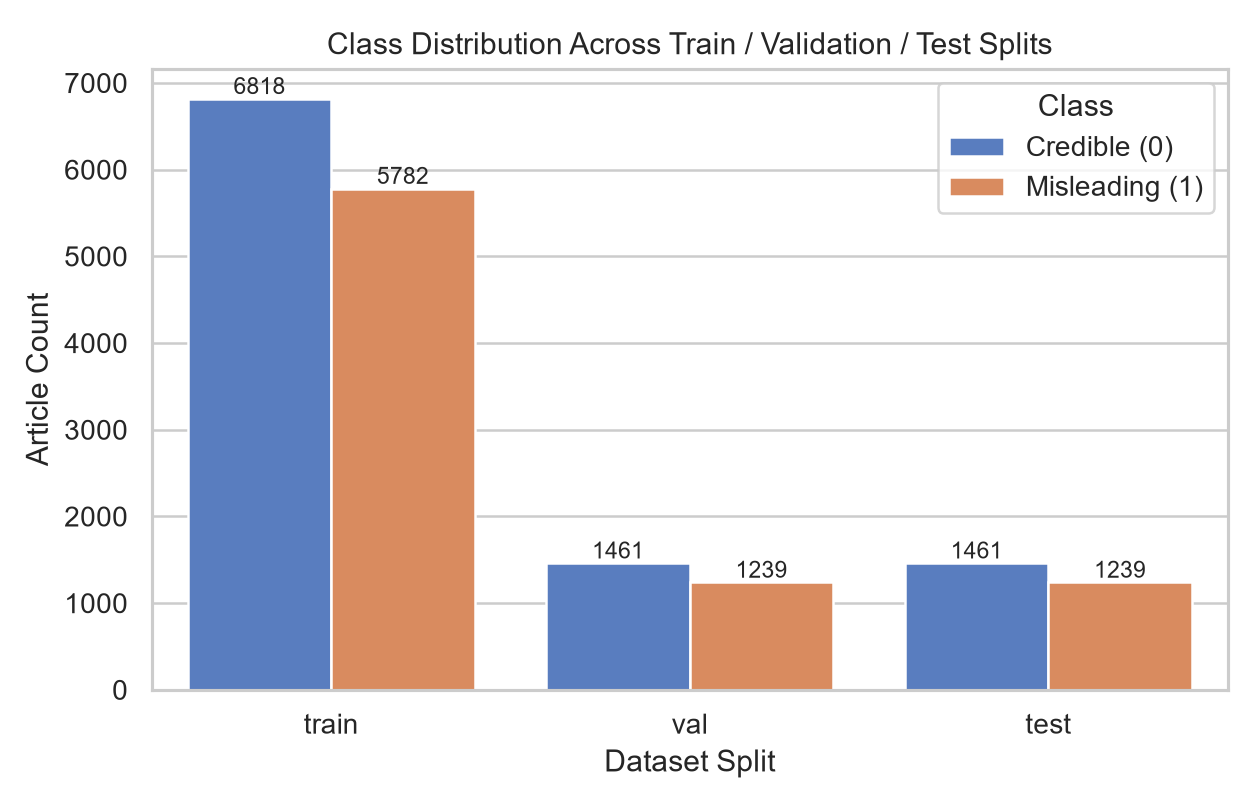

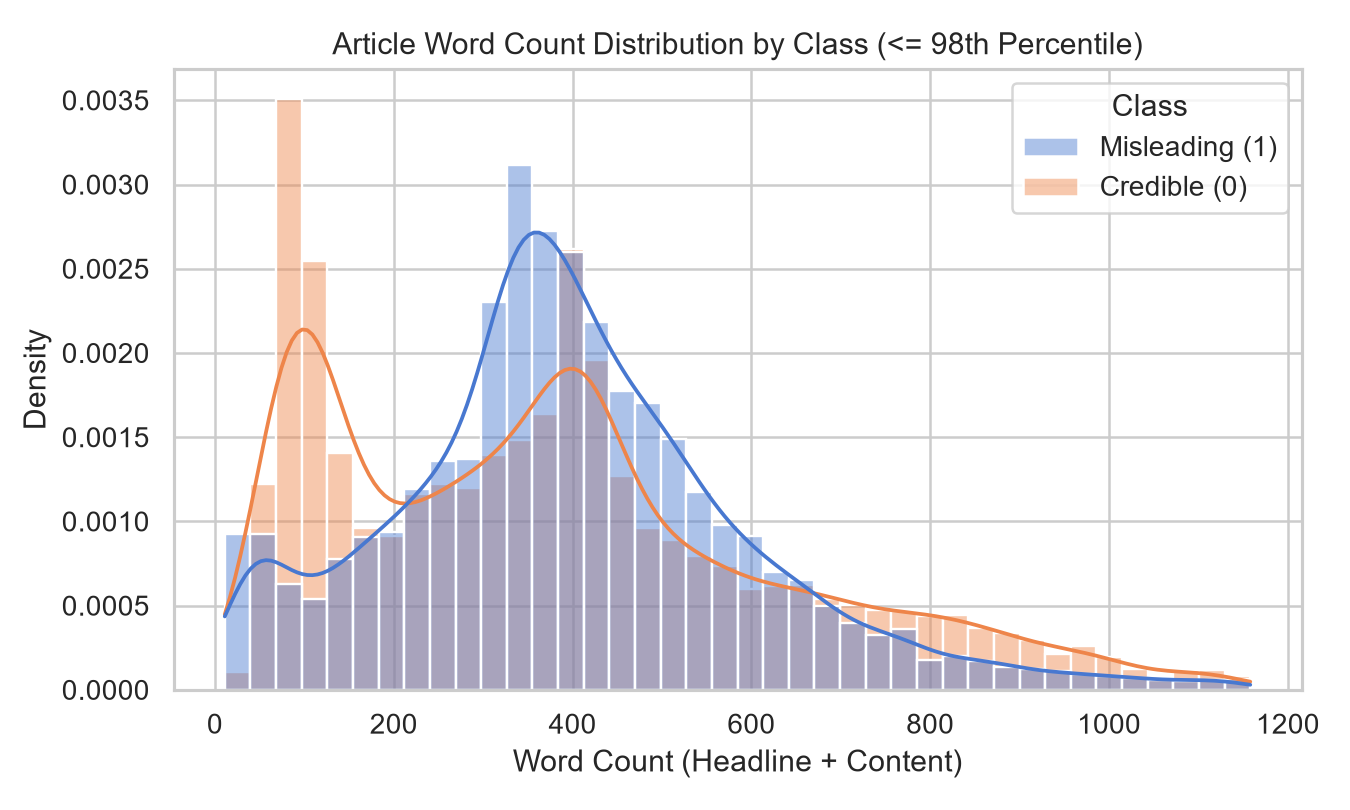

In [3]:
display(Image(filename=str(FIGURES_DIR / "class_distribution.png")))
display(Image(filename=str(FIGURES_DIR / "text_length_distribution.png")))

---
## 3. Model / Technical Approach

### Workflow & Experimental Design
1. **Baseline 1 (`TF-IDF + Multinomial Naive Bayes`):** Fast probabilistic bag-of-ngrams (1–2 grams, 25k features) baseline.
2. **Baseline 2 (`TF-IDF + Logistic Regression`):** Linear discriminative classifier over TF-IDF n-grams with balanced class weights.
3. **Primary Transformer (`distilbert-base-uncased`):** 6-layer distilled BERT encoder fine-tuned end-to-end with AdamW (`lr=2e-5`), linear warmup, gradient clipping, and mixed precision (`fp16`) over structured input:
   `Headline: <headline> [SEP] Description: <description> [SEP] Content: <content>`

In [4]:
with open(OUTPUTS_DIR / "transformer_metrics.json", encoding="utf-8") as f:
    transformer_info = json.load(f)

print("Transformer Hyperparameters:", json.dumps(transformer_info["hyperparameters"], indent=2))
pd.DataFrame(transformer_info["history"])

Transformer Hyperparameters: {
  "epochs": 2,
  "batch_size": 32,
  "learning_rate": 2e-05,
  "max_length": 256,
  "fp16": true
}


,epoch,train_loss,val_loss,val_accuracy,val_f1,val_roc_auc,epoch_sec
0,1,0.1545,0.0332,0.9867,0.9856,0.9994,127.86
1,2,0.0362,0.0295,0.9874,0.9864,0.9996,123.78


---
## 4. Evaluation, Results & Interpretation

We evaluate all models on the held-out test set using **Accuracy, Precision, Recall, F1-Score, and ROC-AUC**, and inspect training curves, confusion matrix, ROC curves, and high-confidence misclassifications.

In [5]:
with open(OUTPUTS_DIR / "comparison_metrics.json", encoding="utf-8") as f:
    comparison = json.load(f)

rows = []
for model_name, metrics in comparison.items():
    t = metrics["test"]
    rows.append({
        "Model": model_name,
        "Accuracy": t["accuracy"],
        "Precision": t["precision"],
        "Recall": t["recall"],
        "F1-Score": t["f1_score"],
        "ROC-AUC": t["roc_auc"],
        "Train Time (s)": metrics.get("train_time_sec"),
    })

comparison_df = pd.DataFrame(rows)
comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Time (s)
0,TF-IDF + Multinomial Naive Bayes,0.9374,0.9154,0.9516,0.9331,0.9809,15.64
1,TF-IDF + Logistic Regression,0.9648,0.9576,0.9661,0.9618,0.9925,14.20
2,DistilBERT (Fine-Tuned),0.9822,0.9768,0.9847,0.9807,0.9991,252.49


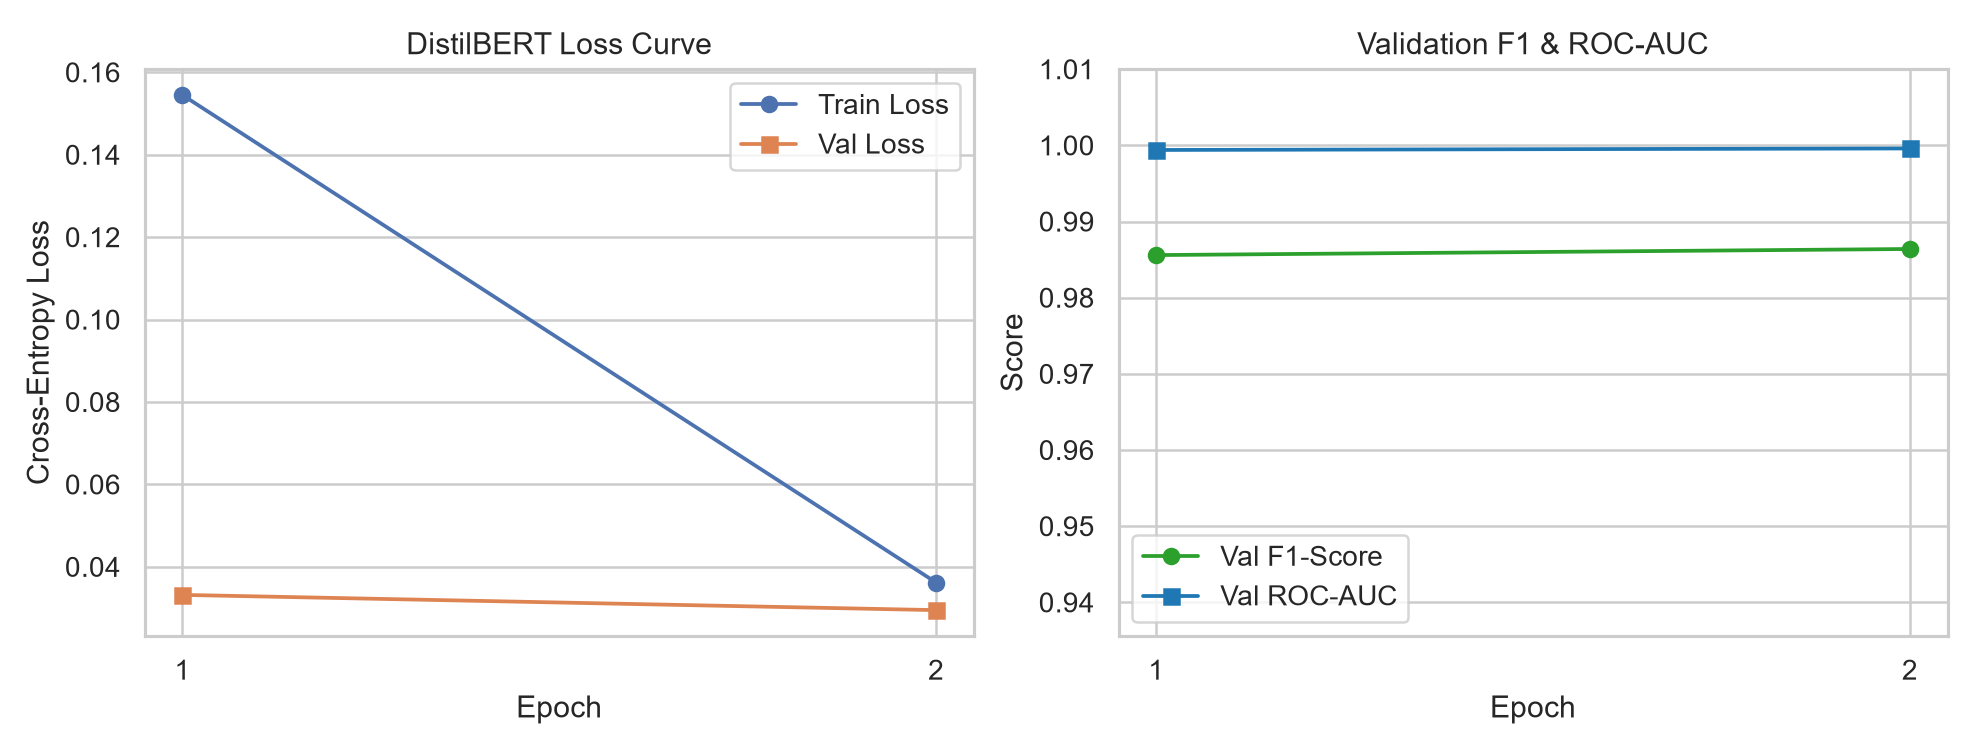

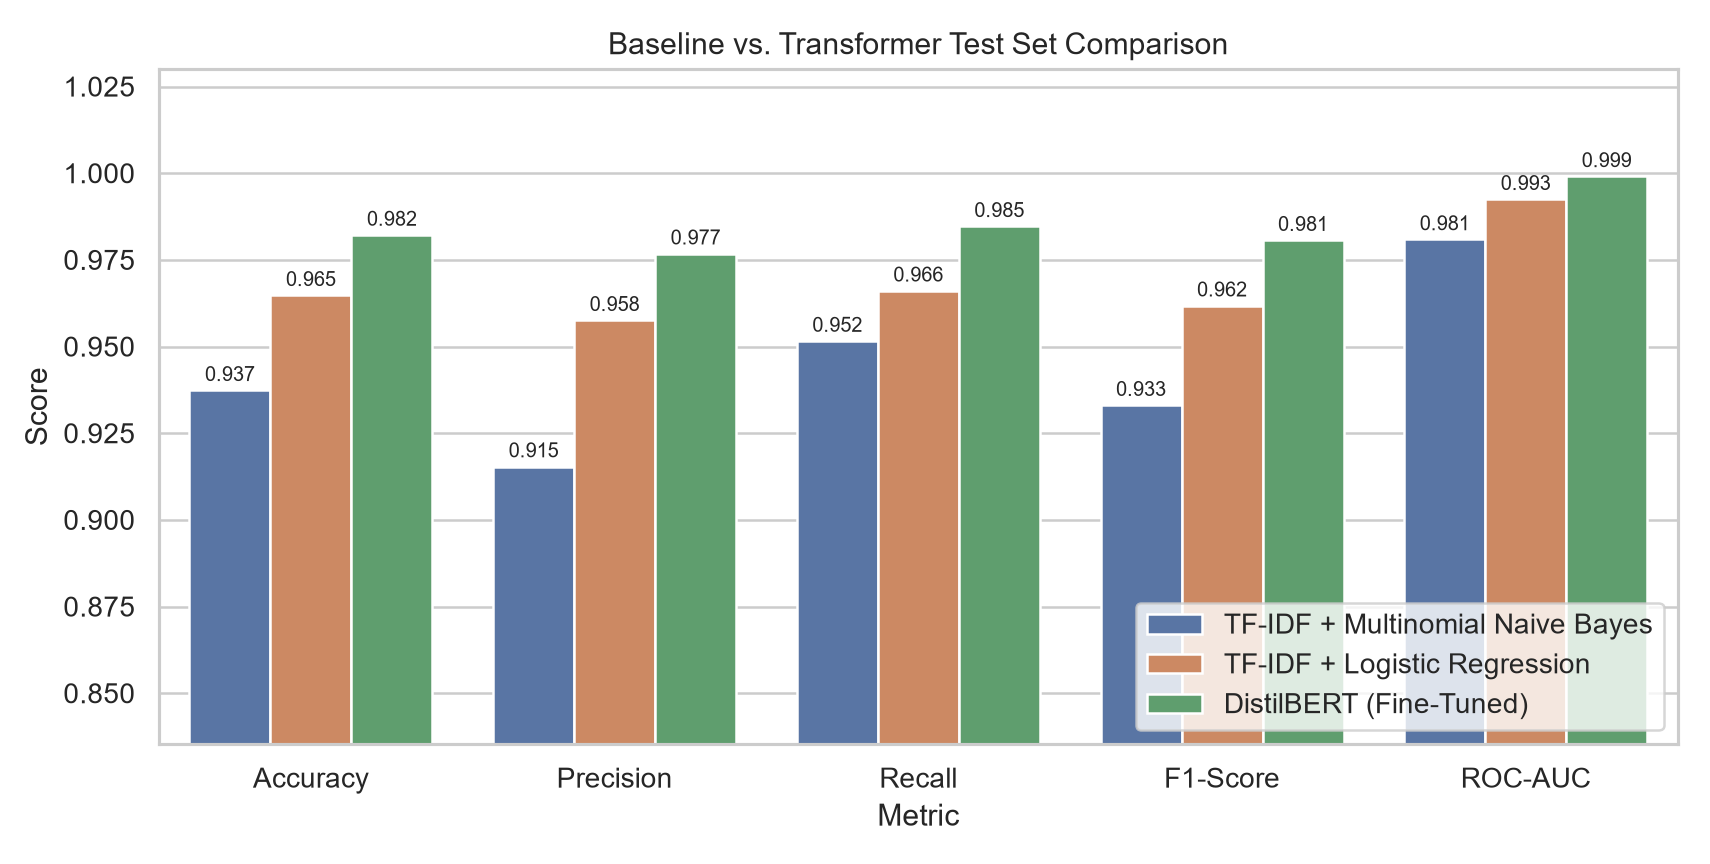

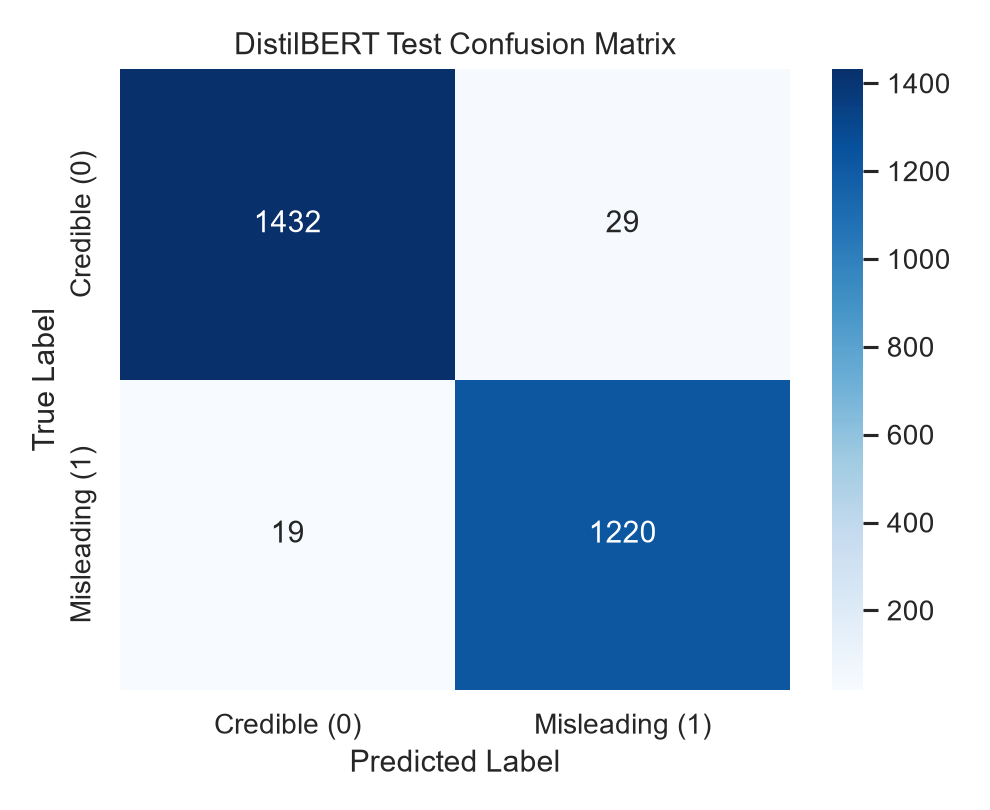

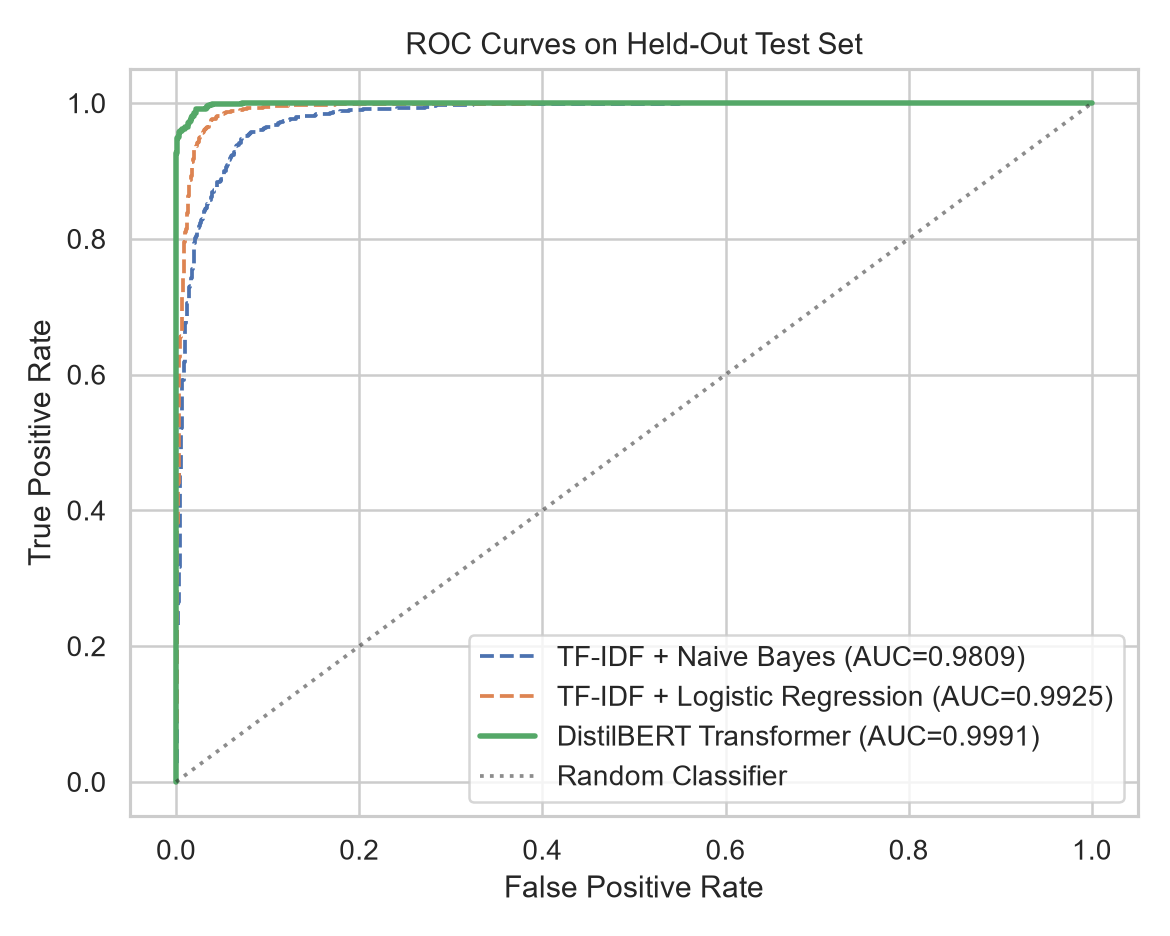

In [6]:
display(Image(filename=str(FIGURES_DIR / "training_history.png")))
display(Image(filename=str(FIGURES_DIR / "model_comparison.png")))
display(Image(filename=str(FIGURES_DIR / "confusion_matrix_distilbert.png")))
display(Image(filename=str(FIGURES_DIR / "roc_curves.png")))

### Error Analysis & Limitations
Inspecting the highest-confidence misclassifications helps reveal model limitations:
- **Stylistic Ambiguity:** Opinion pieces or satirical articles with neutral journalistic phrasing can resemble credible reporting (False Negatives).
- **Clickbait Credible Headlines:** Genuine breaking news with dramatic headlines can occasionally trigger False Positives.
- **No External Fact Verification:** The classifier evaluates linguistic and contextual patterns learned from historical labelled data; it does not cross-check claims against live external knowledge bases.
- **Sequence Truncation (`max_length=256`):** Very long investigative articles are truncated after the first 256 WordPiece tokens.

In [7]:
error_df = pd.read_csv(OUTPUTS_DIR / "error_analysis.csv")
error_df[["error_type", "label", "pred_label", "model_confidence", "headline"]].head(8)

,error_type,label,pred_label,model_confidence,headline
0,False Negative (Missed Misleading),1,0,0.9987,IRAN MAY HAVE RECEIVED Over $33 Billion In Cas...
1,False Negative (Missed Misleading),1,0,0.9967,MIGRANT GIRLS AS YOUNG AS 11 Arrive In Sweden ...
2,False Negative (Missed Misleading),1,0,0.9942,Federal Judge Rules Same-Sex Couples Can Adopt...
3,False Positive (Flagged Credible),0,1,0.9915,things you need to know about the jfk assassin...
4,False Negative (Missed Misleading),1,0,0.9901,a conundrum of the current political season
5,False Negative (Missed Misleading),1,0,0.9883,Donald Trump Effigies Burned Across Mexico Dur...
6,False Negative (Missed Misleading),1,0,0.9779,Republicans Block Young Voters From Participat...
7,False Negative (Missed Misleading),1,0,0.9661,Bernie Sanders Gave EXCELLENT Speech On Israel...


---
## 5. Live Demonstration Prototype

Below we load the saved fine-tuned `distilbert-base-uncased` model via [`FakeNewsDetector`](../src/predict.py) and run predictions on unseen sample articles. An interactive Streamlit web dashboard is also provided in [`app.py`](../app.py).

In [8]:
import sys
sys.path.insert(0, str(PROJECT_ROOT))
from src.predict import FakeNewsDetector

detector = FakeNewsDetector()

samples = [
    {
        "headline": "Central bank holds interest rates steady as inflation cools gradually",
        "description": "Monetary policymakers cited balanced employment figures in their quarterly review.",
        "content": (
            "The central bank kept its benchmark lending rate unchanged on Wednesday following two days of policy "
            "meetings. Officials noted that consumer price growth has moderated over recent quarters while labor "
            "markets remain stable."
        ),
    },
    {
        "headline": "SHOCKING LEAK: Secret directive orders nationwide internet shutdown this weekend!!",
        "description": "Unverified viral posts claim citizens must prepare immediately before news is deleted.",
        "content": (
            "YOU WON'T HEAR THIS ON MAINSTREAM NEWS!! Anonymous insiders say a secret order has already been signed "
            "to shut down internet access across every major city this Saturday. Share this before they censor it!"
        ),
    },
]

for idx, s in enumerate(samples, start=1):
    res = detector.predict(s["headline"], s["description"], s["content"])
    print(f"Sample {idx}: {res['prediction']} | Confidence={res['confidence']:.2%} | Probs={res['probabilities']}")

W1127 09:59:05.524000 8376 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Sample 1: Credible | Confidence=99.90% | Probs={'Credible': 0.999, 'Misleading': 0.001}
Sample 2: Misleading | Confidence=99.88% | Probs={'Credible': 0.0012, 'Misleading': 0.9988}
